In [4]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [5]:
import numpy as np
import os

In [6]:
train = np.load('/content/drive/MyDrive/Member3_Prepared_Data/train_data.npz')
print(train.files)
X_train = train['X_hog']
Y_train = train['y']
print(X_train.shape, Y_train.shape)

['X_raw', 'X_hog', 'X_color', 'y', 'image_paths']
(3021, 1764) (3021,)


In [7]:
test = np.load('/content/drive/MyDrive/Member3_Prepared_Data/test_data.npz')
print(test.files)
X_test = test['X_hog']
Y_test = test['y']
print(X_test.shape, Y_test.shape)

['X_raw', 'X_hog', 'X_color', 'y', 'image_paths']
(648, 1764) (648,)


In [8]:
validation = np.load('/content/drive/MyDrive/Member3_Prepared_Data/validation_data.npz')
print(validation.files)
X_validation = validation['X_hog']
Y_validation = validation['y']
print(X_validation.shape, Y_validation.shape)

['X_raw', 'X_hog', 'X_color', 'y', 'image_paths']
(648, 1764) (648,)


In [9]:
from sklearn.preprocessing import StandardScaler
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)

In [10]:
X_validation_scaled = scaler.transform(X_validation)
X_test_scaled = scaler.transform(X_test)

In [11]:
print("Original shapes:")
print("X_train:", X_train.shape)
print("X_validation:", X_validation.shape)
print("X_test:", X_test.shape)

print("\nScaled shapes:")
print("X_train_scaled:", X_train_scaled.shape)
print("X_validation_scaled:", X_validation_scaled.shape)
print("X_test_scaled:", X_test_scaled.shape)


print("\nMean of X_train_scaled:", X_train_scaled.mean())
print("Standard deviation of X_train_scaled:", X_train_scaled.std())

Original shapes:
X_train: (3021, 1764)
X_validation: (648, 1764)
X_test: (648, 1764)

Scaled shapes:
X_train_scaled: (3021, 1764)
X_validation_scaled: (648, 1764)
X_test_scaled: (648, 1764)

Mean of X_train_scaled: -1.8325284e-10
Standard deviation of X_train_scaled: 1.0


In [12]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score
C_values = [0.001, 0.01, 0.1, 1, 10]
results = {}

In [13]:
for c in C_values:
    log_reg = LogisticRegression(
        C=c,
        random_state=42,
        max_iter=1000
    )
    log_reg.fit(X_train_scaled, Y_train)

    Y_validation_pred = log_reg.predict(X_validation_scaled)

    accuracy = accuracy_score(Y_validation, Y_validation_pred)

    results[c] = accuracy

    print(f"C = {c:<6} | Accuracy = {accuracy:.4f}")

C = 0.001  | Accuracy = 0.3858
C = 0.01   | Accuracy = 0.3503
C = 0.1    | Accuracy = 0.3272
C = 1      | Accuracy = 0.3133
C = 10     | Accuracy = 0.3086


In [14]:
C_values = [0.00001, 0.0001, 0.001, 0.01, 0.1, 1, 10]

In [15]:
results = {}
for c in C_values:
    log_reg = LogisticRegression(
        C=c,
        random_state=42,
        max_iter=1000
    )
    log_reg.fit(X_train_scaled, Y_train)

    Y_validation_pred = log_reg.predict(X_validation_scaled)

    accuracy = accuracy_score(Y_validation, Y_validation_pred)

    results[c] = accuracy

    print(f"C = {c:<10} | Accuracy = {accuracy:.4f}")

C = 1e-05      | Accuracy = 0.3287
C = 0.0001     | Accuracy = 0.4198
C = 0.001      | Accuracy = 0.3858
C = 0.01       | Accuracy = 0.3503
C = 0.1        | Accuracy = 0.3272
C = 1          | Accuracy = 0.3133
C = 10         | Accuracy = 0.3086


In [16]:
best_C = max(results, key=results.get)
best_accuracy = results[best_C]

print("\nBest C:", best_C)
print("Best Validation Accuracy:", best_accuracy)


Best C: 0.0001
Best Validation Accuracy: 0.41975308641975306


In [17]:
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score

In [18]:
k_values = [1, 3, 5, 7, 9, 11, 15, 21]

results_knn = {}

In [19]:
for k in k_values:
    knn = KNeighborsClassifier(n_neighbors=k)

    knn.fit(X_train_scaled, Y_train)

    Y_validation_pred = knn.predict(X_validation_scaled)

    accuracy = accuracy_score(Y_validation, Y_validation_pred)

    results_knn[k] = accuracy

    print(f"k = {k:<3} | Accuracy = {accuracy:.4f}")

k = 1   | Accuracy = 0.3241
k = 3   | Accuracy = 0.2994
k = 5   | Accuracy = 0.2809
k = 7   | Accuracy = 0.2948
k = 9   | Accuracy = 0.2840
k = 11  | Accuracy = 0.2917
k = 15  | Accuracy = 0.3009
k = 21  | Accuracy = 0.2994


In [20]:
best_k = max(results_knn, key=results_knn.get)

print("Best k:", best_k)
print("Best Accuracy:", results_knn[best_k])

Best k: 1
Best Accuracy: 0.32407407407407407


In [21]:
from sklearn.cluster import KMeans
from sklearn.metrics import accuracy_score, silhouette_score
from collections import Counter

kmeans = KMeans(
    n_clusters=5,
    random_state=42,
    n_init=10
)
kmeans.fit(X_train_scaled)

KMeans(n_clusters=5, n_init=10, random_state=42)

In [22]:
y_train_array = np.asarray(Y_train).ravel()

train_clusters = kmeans.labels_

cluster_to_class = {}

for cluster in range(5):

    cluster_mask = (train_clusters == cluster)
    cluster_labels = y_train_array[cluster_mask]

    if len(cluster_labels) > 0:
        most_common_class = Counter(cluster_labels).most_common(1)[0][0]
        cluster_to_class[cluster] = most_common_class

print("Cluster to Class Mapping:")
print(cluster_to_class)

Cluster to Class Mapping:
{0: np.str_('sunflower'), 1: np.str_('daisy'), 2: np.str_('tulip'), 3: np.str_('dandelion'), 4: np.str_('dandelion')}


In [23]:
validation_clusters = kmeans.predict(X_validation_scaled)

Y_validation_pred = np.array([
    cluster_to_class[cluster]
    for cluster in validation_clusters
])

kmeans_accuracy = accuracy_score(
    Y_validation,
    Y_validation_pred
)
print("KMeans Validation Accuracy:", kmeans_accuracy)

KMeans Validation Accuracy: 0.29475308641975306


In [24]:
silhouette = silhouette_score(
    X_train_scaled,
    train_clusters
)

print("Silhouette Score:", silhouette)

Silhouette Score: 0.01227188


In [25]:
train = np.load('/content/drive/MyDrive/Member3_Prepared_Data/train_data.npz')
print(train.files)
X_train_color = train['X_color']
print(X_train_color.shape, Y_train.shape)

['X_raw', 'X_hog', 'X_color', 'y', 'image_paths']
(3021, 96) (3021,)


In [28]:
validation = np.load('/content/drive/MyDrive/Member3_Prepared_Data/validation_data.npz')
print(validation.files)
X_validation_color = validation['X_color']
print(X_validation_color.shape, Y_validation.shape)

['X_raw', 'X_hog', 'X_color', 'y', 'image_paths']
(648, 96) (648,)


In [29]:
test = np.load('/content/drive/MyDrive/Member3_Prepared_Data/test_data.npz')
print(test.files)
X_test_color = test['X_color']
print(X_test_color.shape, Y_test.shape)

['X_raw', 'X_hog', 'X_color', 'y', 'image_paths']
(648, 96) (648,)


In [30]:
scaler_color = StandardScaler()
X_train_color_scaled = scaler_color.fit_transform(X_train_color)

In [33]:
X_validation_color_scaled = scaler_color.transform(X_validation_color)
X_test_color_scaled = scaler_color.transform(X_test_color)

In [34]:
print("Original shapes:")
print("X_train_color:", X_train_color.shape)
print("X_validation_color:", X_validation_color.shape)
print("X_test_color:", X_test_color.shape)

print("\nScaled shapes:")
print("X_train_color_scaled:", X_train_color_scaled.shape)
print("X_validation_color_scaled:", X_validation_color_scaled.shape)
print("X_test_color_scaled:", X_test_color_scaled.shape)


print("\nMean of X_train_color_scaled:", X_train_color_scaled.mean())
print("Standard deviation of X_train_color_scaled:", X_train_color_scaled.std())

Original shapes:
X_train_color: (3021, 96)
X_validation_color: (648, 96)
X_test_color: (648, 96)

Scaled shapes:
X_train_color_scaled: (3021, 96)
X_validation_color_scaled: (648, 96)
X_test_color_scaled: (648, 96)

Mean of X_train_color_scaled: 7.938039500795559e-18
Standard deviation of X_train_color_scaled: 0.9999999999999993


In [35]:
results_color = {}
for c in C_values:
    log_reg = LogisticRegression(
        C=c,
        random_state=42,
        max_iter=1000
    )
    log_reg.fit(X_train_color_scaled, Y_train)

    Y_validation_pred = log_reg.predict(X_validation_color_scaled)

    accuracy = accuracy_score(Y_validation, Y_validation_pred)

    results_color[c] = accuracy

    print(f"C = {c:<10} | Accuracy = {accuracy:.4f}")

C = 1e-05      | Accuracy = 0.2454
C = 0.0001     | Accuracy = 0.3472
C = 0.001      | Accuracy = 0.4306
C = 0.01       | Accuracy = 0.4414
C = 0.1        | Accuracy = 0.4321
C = 1          | Accuracy = 0.4321
C = 10         | Accuracy = 0.4321


In [36]:
best_C_color = max(results_color, key=results_color.get)
best_accuracy_color = results_color[best_C_color]

print("\nBest C:", best_C_color)
print("Best Validation Accuracy:", best_accuracy_color)


Best C: 0.01
Best Validation Accuracy: 0.44135802469135804


In [37]:
k_values = [1, 3, 5, 7, 9, 11, 15, 21]

results_color_knn = {}

In [38]:
for k in k_values:
    knn = KNeighborsClassifier(n_neighbors=k)

    knn.fit(X_train_color_scaled, Y_train)

    Y_validation_pred = knn.predict(X_validation_color_scaled)

    accuracy = accuracy_score(Y_validation, Y_validation_pred)

    results_color_knn[k] = accuracy

    print(f"k = {k:<3} | Accuracy = {accuracy:.4f}")

k = 1   | Accuracy = 0.3843
k = 3   | Accuracy = 0.3951
k = 5   | Accuracy = 0.3889
k = 7   | Accuracy = 0.4074
k = 9   | Accuracy = 0.4275
k = 11  | Accuracy = 0.4414
k = 15  | Accuracy = 0.4167
k = 21  | Accuracy = 0.4367


In [40]:
best_k_color = max(results_color_knn, key=results_color_knn.get)

print("Best k:", best_k_color)
print("Best Accuracy:", results_color_knn[best_k_color])

Best k: 11
Best Accuracy: 0.44135802469135804


In [41]:
from sklearn.cluster import KMeans
from sklearn.metrics import accuracy_score, silhouette_score
from collections import Counter

kmeans_color = KMeans(
    n_clusters=5,
    random_state=42,
    n_init=10
)
kmeans_color.fit(X_train_color_scaled)

KMeans(n_clusters=5, n_init=10, random_state=42)

In [42]:
y_train_array = np.asarray(Y_train).ravel()

train_clusters_color = kmeans_color.labels_

cluster_to_class_color = {}

for cluster in range(5):

    cluster_mask = (train_clusters_color == cluster)
    cluster_labels = y_train_array[cluster_mask]

    if len(cluster_labels) > 0:
        most_common_class = Counter(cluster_labels).most_common(1)[0][0]
        cluster_to_class_color[cluster] = most_common_class

print("Cluster to Class Mapping:")
print(cluster_to_class_color)

Cluster to Class Mapping:
{0: np.str_('dandelion'), 1: np.str_('dandelion'), 2: np.str_('tulip'), 3: np.str_('dandelion'), 4: np.str_('sunflower')}


In [43]:
validation_clusters = kmeans_color.predict(X_validation_color_scaled)

Y_validation_pred = np.array([
    cluster_to_class_color[cluster]
    for cluster in validation_clusters
])

kmeans_color_accuracy = accuracy_score(
    Y_validation,
    Y_validation_pred
)
print("KMeans Validation Accuracy:", kmeans_color_accuracy)

KMeans Validation Accuracy: 0.2824074074074074


In [44]:
silhouette_color = silhouette_score(
    X_train_color_scaled,
    train_clusters_color
)

print("Silhouette Score:", silhouette_color)

Silhouette Score: 0.08065843814093578


In [45]:
from sklearn.metrics import (
    confusion_matrix,
    classification_report,
    ConfusionMatrixDisplay
)
import matplotlib.pyplot as plt

In [46]:
final_log_reg = LogisticRegression(
    C=0.01,
    random_state=42,
    max_iter=1000
)

final_log_reg.fit(X_train_color_scaled, Y_train)

LogisticRegression(C=0.01, max_iter=1000, random_state=42)

In [47]:
Y_test_pred_lr = final_log_reg.predict(X_test_color_scaled)

In [48]:
accuracy_lr = accuracy_score(Y_test, Y_test_pred_lr)

print("Logistic Regression Test Accuracy:", accuracy_lr)

Logistic Regression Test Accuracy: 0.4367283950617284


In [49]:
print(classification_report(Y_test, Y_test_pred_lr))

              precision    recall  f1-score   support

       daisy       0.38      0.33      0.35       115
   dandelion       0.41      0.51      0.45       158
        rose       0.53      0.31      0.39       117
   sunflower       0.50      0.50      0.50       110
       tulip       0.43      0.50      0.46       148

    accuracy                           0.44       648
   macro avg       0.45      0.43      0.43       648
weighted avg       0.44      0.44      0.43       648



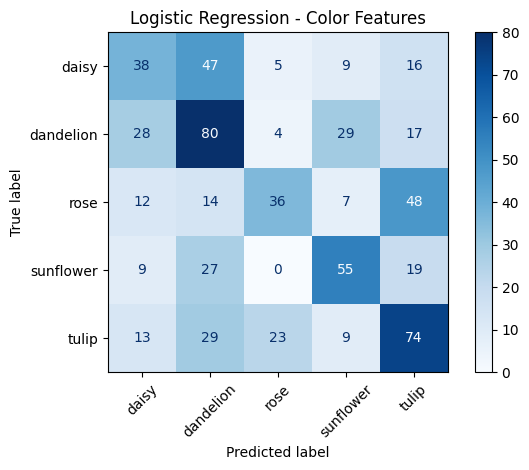

In [50]:
cm_lr = confusion_matrix(Y_test, Y_test_pred_lr)

disp_lr = ConfusionMatrixDisplay(
    confusion_matrix=cm_lr,
    display_labels=final_log_reg.classes_
)

disp_lr.plot(cmap="Blues")
plt.title("Logistic Regression - Color Features")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [51]:
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)
import matplotlib.pyplot as plt

In [52]:
final_knn = KNeighborsClassifier(n_neighbors=11)

final_knn.fit(X_train_color_scaled, Y_train)

KNeighborsClassifier(n_neighbors=11)

In [53]:
Y_test_pred_knn = final_knn.predict(X_test_color_scaled)

In [54]:
accuracy_knn = accuracy_score(Y_test, Y_test_pred_knn)

print("KNN Test Accuracy:", accuracy_knn)

KNN Test Accuracy: 0.4506172839506173


In [55]:
print("\nClassification Report:")
print(classification_report(Y_test, Y_test_pred_knn))


Classification Report:
              precision    recall  f1-score   support

       daisy       0.43      0.53      0.48       115
   dandelion       0.46      0.47      0.47       158
        rose       0.41      0.38      0.39       117
   sunflower       0.54      0.45      0.50       110
       tulip       0.42      0.42      0.42       148

    accuracy                           0.45       648
   macro avg       0.45      0.45      0.45       648
weighted avg       0.45      0.45      0.45       648



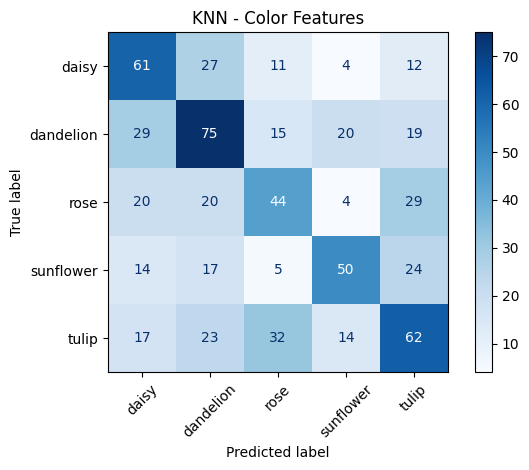

In [56]:
cm_knn = confusion_matrix(Y_test, Y_test_pred_knn)

disp_knn = ConfusionMatrixDisplay(
    confusion_matrix=cm_knn,
    display_labels=final_knn.classes_
)

disp_knn.plot(cmap="Blues")
plt.title("KNN - Color Features")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [57]:
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)
import matplotlib.pyplot as plt
import numpy as np

In [58]:
test_clusters_color = kmeans_color.predict(X_test_color_scaled)

In [59]:
Y_test_pred_km = np.array([
    cluster_to_class_color[cluster]
    for cluster in test_clusters_color
])

In [60]:
class_labels = final_knn.classes_

In [61]:
accuracy_km = accuracy_score(Y_test, Y_test_pred_km)
print("K-Means Test Accuracy:", accuracy_km)

K-Means Test Accuracy: 0.2932098765432099


In [62]:
print("\nClassification Report:")
print(classification_report(
    Y_test,
    Y_test_pred_km,
    labels=class_labels,
    zero_division=0
))


Classification Report:
              precision    recall  f1-score   support

       daisy       0.00      0.00      0.00       115
   dandelion       0.31      0.69      0.43       158
        rose       0.00      0.00      0.00       117
   sunflower       0.24      0.29      0.26       110
       tulip       0.30      0.33      0.31       148

    accuracy                           0.29       648
   macro avg       0.17      0.26      0.20       648
weighted avg       0.18      0.29      0.22       648



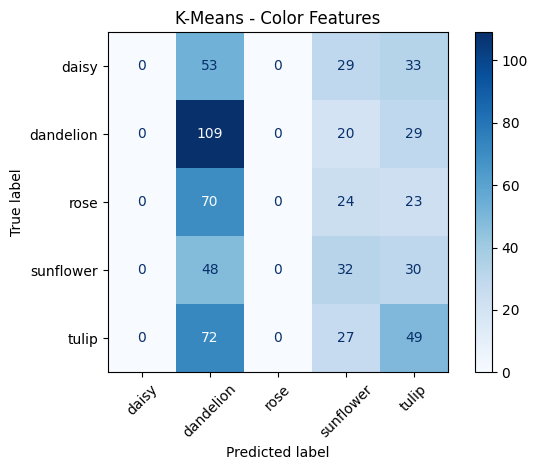

In [63]:
cm_km = confusion_matrix(
    Y_test,
    Y_test_pred_km,
    labels=class_labels
)

disp_km = ConfusionMatrixDisplay(
    confusion_matrix=cm_km,
    display_labels=class_labels
)

disp_km.plot(cmap="Blues")
plt.title("K-Means - Color Features")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [64]:
import os
import joblib


models_path = "/content/drive/MyDrive/models"
os.makedirs(models_path, exist_ok=True)


joblib.dump(final_log_reg, os.path.join(models_path, "final_log_reg.pkl"))
joblib.dump(final_knn, os.path.join(models_path, "final_knn.pkl"))
joblib.dump(kmeans_color, os.path.join(models_path, "kmeans_color.pkl"))
joblib.dump(scaler_color, os.path.join(models_path, "scaler_color.pkl"))
joblib.dump(cluster_to_class_color, os.path.join(models_path, "cluster_to_class_color.pkl"))

print("All models saved successfully!")

All models saved successfully!
